# Quantum Metal A.7 — IMS 2022 workshop chip: three all-to-all coupled qubits with stated targets (Quantcore PDK rebuild)

**What the chip is.** The chip of the Qiskit Metal IMS 2022 workshop,
`docs/circuit-examples/full-design-flow-examples/A.7-IMS-2022-workshop.ipynb` (© IBM / Qiskit Metal contributors,
Apache-2.0, <https://github.com/qiskit-community/qiskit-metal>; spec `docs/designs/metal/A7_ims2022_3q.md`): three
`TransmonPocket6` qubits in a triangle, coupled all-to-all by three λ/2 buses. `Q_0` and `Q_1` are read out through
`CapNInterdigitalTee`s on a short north feedline (two launchpads), `Q_2` through a series `CapNInterdigital` to its
own south launchpad. The tutorial states targets (f_q 4.8 / 5.0 / 5.2 GHz, α −300 MHz, readouts 6.8 / 7.0 / 7.2 GHz,
buses 5.8 / 6.0 / 6.2 GHz) and tunes `Q_0`, `Q_1`, `Bus_01` and `Bus_02` with Q3D-LOM and HFSS-EPR sweeps; this
rebuild uses the **tuned** state (the values at the end of the tutorial). We distribute the rebuild under GPL-3.0.

**This notebook rebuilds it with our library and the Quantcore PDK** (PDK v3, `quantcore_nb_sapphire_v1`): the Metal
components are drawn through the `metal:<Class>` wrapper with the tutorial's tuned options; the chip, the stack, the
junctions, the routes, the netlist and the LOM are ours.

| | Qiskit Metal tutorial | Quantcore PDK rebuild |
|---|---|---|
| chip | `DesignPlanar` 6 × 6 mm centred on (0, 0) | the 7.5 × 7.5 mm Quantcore die with the QCT frame, the source's 6 × 6 mm area centred in it (`box=(-750, -750, 6750, 6750)`) |
| substrate | silicon 750 µm, εr 11.45 (Metal default) | sapphire 650 µm, εr 10.25 (LOM and FEM) |
| launchpads | 3 `LaunchpadWirebond`s at the 6 mm chip's edge (outer edge 990 µm from the 7.5 mm die edge) | the same pads, moved to **100 µm** (`frame.pad_edge`) from the die edge (PDK pad rule) |
| junctions | Metal junction line, `hfss_inductance` 14.9 / 13.9 / 14.0 nH (tuned) | Quantcore Nb/AlOx/Nb trilayer junctions **sized for the stated targets** 4.8 / 5.0 / 5.2 GHz: L_J 15.3 / 14.6 / 14.6 nH, R_n ≈ 98–102 kΩ (outside the 40–50 kΩ window: flagged) |
| cheese | Metal's GDS cheese, set explicitly: 3 µm squares every 50 µm, `no_cheese.buffer` 40 µm | the original's Metal rule, drawn by the build (chip `cheese` = `metal_cheese_rule(buffer=40, size=3, pitch=50)`) |
| routes | `RouteMeander` buses 9550 / 9350 / 9700 µm, readouts 8800 / 8500 / 8300 µm, `RoutePathfinder` feedline | qcc meanders / serpentines of the same lengths on the same pins (turn radius 99 µm = Metal's fillet), qcc `cpw` feedline |
| placement | as drawn | content centred in the die |

**Kept exactly:** the three qubits with the tuned options (`pad_gap` 28 µm on `Q_0`/`Q_1`; readout pads 100 × 22 /
100 × 20 µm; bus pads 135 / 130 µm where tuned, else 60 × 10 µm), the tees and the series cap (Metal defaults), the
three launchpads and their positions along the edges, every route's end pins and total length, the 10/6 µm CPW, the
99 µm fillet and all the stated targets.

**Simplified:** the readouts are laid out as serpentines through waypoints (200 µm run pitch, as Metal's meander
spacing) and `Bus_02`/`Bus_12` as qcc meanders on one vertical segment; `Bus_01` meanders between the qubits as in
the source. Metal's `RouteMeander`s with jogs and asymmetry give different footprints with the same end points and
lengths.

**How this notebook goes.** First the **Design**: the chip is laid out one segment at a time, each segment its own cell with a
picture of the chip so far — the die (with the tutorial's targets), the three launchpads, the readout line (the two
feedline tees, `Q_2`'s series capacitor and their pad lines), the three qubits with junctions sized for the targets,
their readout resonators, the three coupling buses, and then the whole chip. Then the same steps as the Flow strip of the Quantcore
KLayout plugin: **Check** (DRC, netlist) → **LOM** (simulation and plots) → **Simulate** (export to HFSS, the
component simulation, the eigenmode simulation, the full-wave run) → **Results** (plots, the values, FEM against the
LOM, a feedback step and the iteration to a target) → **Fab**.

**Nothing here solves on its own.** The switches (the code cell after Setup) are off (`RUN_FEM = False`): FEM results
are loaded when a solve has been kept, otherwise each FEM cell says what would appear. The notebook before this
rewrite (the layout in one cell, with its outputs) is kept as `a7_ims2022_3q.v1.ipynb`; both save the same
`a7_ims2022_3q.json`.

## Setup

The imports, the output folder, the chip's two helpers (`pad`: a Metal connection-pad entry; `serp`: serpentine waypoints) and the switches. `LIVE`: with KLayout open (the default) every change below is pushed to the KLayout window as you run it;
with `QCC_LIVE=0` the notebook builds headless and only writes files. `_common` holds the helpers the design
notebooks share (tables, snapshots, the PDK placement, the FEM and feedback steps).

**The switches** (next cell): `RUN_FEM` solves the FEM jobs in AEDT 2024 R1 or newer, one after the other (a new
non-graphical AEDT unless `AEDT_MODE` says otherwise; an AEDT you have open is never touched); `RESOLVE` solves again
even when kept results match; `FEM_FAST` exports with the library's fast test settings (minutes, values not
converged); `MAX_ITER` caps the feedback iterations towards the targets.

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK placement, FEM and feedback helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction
from quantcore_circuits.lom.simulate import simulate
from quantcore_circuits.pdk import get_pdk

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
OUT = Path("examples/designs/metal")             # this notebook's design JSON and PNG snapshots
from quantcore_circuits.circuit.bridges import size_junction


def pad(loc_w, loc_h, width, gap):
    """TransmonPocket6 connection pad (Metal options)."""
    return {"loc_W": loc_w, "loc_H": loc_h, "pad_width": width, "pad_gap": gap}


def serp(start, ends, pitch, vertical=False):
    """Serpentine waypoints from ``start``: runs to each coordinate in ``ends`` (x for horizontal runs, y for vertical
    ones), stepping ``pitch`` between runs; the last run continues to the next waypoint the caller adds."""
    x, y = start
    pts = [(x, y)]
    for i, e in enumerate(ends):
        if vertical:
            y = e
            pts.append((x, y))
            x += pitch
        else:
            x = e
            pts.append((x, y))
            y += pitch
        pts.append((x, y))
    return pts

In [3]:
RUN_FEM = False        # True (or a set such as {"q3d_cmatrix"}): solve the FEM jobs in AEDT 2024 R1+, one at a time
RESOLVE = False        # True (or a set of analyses): solve again even when kept results match
FEM_FAST = True        # True: the library's fast test settings (minutes, not converged); False: the settings as written
AEDT_MODE = "batch"    # "batch" (no window) | "gui" (a new AEDT window, left open) | "attach" (the AEDT you have open)
MAX_ITER = 3           # feedback iterations towards the targets (Results 5)

## The Quantcore PDK this chip uses

The rebuild takes every process fact from the PDK (`get_pdk()`), not from the source: the stack the LOM and the FEM
jobs use, the die frame, where pads go, which junction is drawn, the cheese and the 3/0 keep-outs. For this chip that means: the standard 7.5 mm die with the QCT frame; the three launchpads go 100 µm from the north and south edges; each qubit's trilayer junction is sized for the tutorial's target (and flagged where that leaves the R_n window); the cheese is the original's (Metal's GDS cheese, 3 µm squares), drawn by the build instead of the PDK band.

In [4]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

# Design: the layout, one segment at a time

The chip is built the way a designer would lay it out by hand: the die, the bond pads, the readout, the qubits, the
coupling, the control lines, and then the whole chip. Each segment is one cell with one picture of the chip so far
(and, live, KLayout redraws after every cell). In the Designer a route always joins two ports, so the feedline and `Q_2`'s pad line are drawn as soon as
the pads and the capacitors exist (segment 3), the readouts and the buses once the qubits are there (segments 5–6).

| segment | what is placed here |
|---|---|
| 1 | the 7.5 × 7.5 mm die with the QCT frame, the original's Metal cheese rule and the tutorial's targets |
| 2 | the three launchpads (two north for the feedline, one south for `Q_2`) |
| 3 | the readout line: the two feedline tees, `Q_2`'s series capacitor and the feedline / pad-line routes |
| 4 | the three `TransmonPocket6` qubits, their trilayer junctions sized for the targets |
| 5 | the three λ/2 readout serpentines (8800 / 8500 / 8300 µm) |
| 6 | the coupling: three λ/2 buses (9550 / 9350 / 9700 µm), all-to-all |
| 7 | control lines: none on this chip |
| 8 | the whole chip: sim groups, centring, save |

## Design 1 · The die, its frame and the tutorial's targets

`Designer(name, box=...)` opens an empty chip. The box is the die (µm): the standard **7.5 × 7.5 mm** Quantcore die,
with the source's 6 × 6 mm chip area centred in it, so `P(x, y) = (x + 3000, y + 3000)` maps a Metal position (its
chip is centred on (0, 0)) onto ours unchanged. The PDK draws the **QCT frame**: L dicing markers in the four corners
(1000/0), a 3 × 3 alignment grid in each corner area (1001/0), the chip boundary (100/0) and the device ID
`name_chip` on a free edge (optional: no free edge, no ID).

**Cheese: the original's.** The source exports its GDS with Metal's cheese on (Fab 1), so the original's cheese wins over the PDK band: `chip={"cheese": metal_cheese_rule(buffer=40, size=3, pitch=50)}` hands the build Metal's rule (3 µm squares every 50 µm, 40 µm clear of every etched shape, none within 200 µm of the die edge), and the build draws it instead of the band (`_common.metal_cheese_rule`). The tutorial's targets are attached to the design here
(`d.targets`): the DRC checks them against the PDK band, the LOM tables show them in brackets, Design 4 sizes the junctions for them and the feedback (Results 4–5) works towards them. They belong to the design (they are saved in its JSON), so they stay in this first cell.

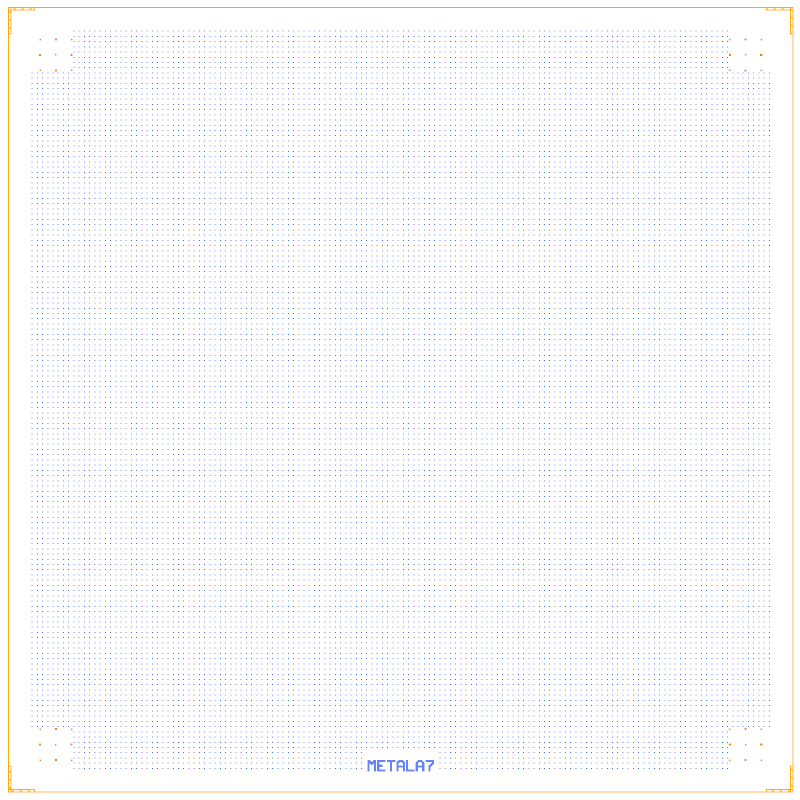

**On the chip so far:** 0 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/metal/a7_ims2022_3q_s1_die.png')

In [5]:
d = Designer("a7_ims2022_3q", box=(-750, -750, 6750, 6750), chip={"name_chip": "MetalA7", "cheese": metal_cheese_rule(buffer=40, size=3, pitch=50)},
             live=LIVE)
X0, Y0 = 3000, 3000                              # Metal's 6 × 6 mm chip is centred on (0, 0)
P = lambda x, y: (X0 + x, Y0 + y)                # Metal µm → Designer µm
R = 99                                           # Metal fillet
TARGETS = {"Q_0": {"f_q_GHz": 4.8, "alpha_MHz": -300}, "Q_1": {"f_q_GHz": 5.0, "alpha_MHz": -300},
           "Q_2": {"f_q_GHz": 5.2, "alpha_MHz": -300},
           "Readout_0": {"f_GHz": 6.8}, "Readout_1": {"f_GHz": 7.0}, "Readout_2": {"f_GHz": 7.2},
           "Bus_01": {"f_GHz": 5.8}, "Bus_02": {"f_GHz": 6.0}, "Bus_12": {"f_GHz": 6.2}}   # tutorial targets
d.targets(**TARGETS)
layout_step(d, OUT / "a7_ims2022_3q_s1_die.png", size=(800, 800), width=400)

## Design 2 · Bond pads: the PDK pad rule

The tutorial puts its three launchpads at the edge of its 6 × 6 mm chip: two on the north side for the `Q_0`/`Q_1`
feedline, one on the south side for `Q_2`. On the 7.5 mm die that leaves their outer edge 990 µm from the die edge.
In the Quantcore PDK the outer edge of every bond pad's etch sits **`frame.pad_edge` = 100 µm from the die
edge**: `edge="n"` / `"s"` slides each pad perpendicular to that edge until it is there; its position along the edge
is kept, so the feedline and `Q_2`'s pad line, which leave the pads along their axis, only get longer. The table
measures it on the built layout; the picture zooms on `Q_2`'s pad at the south edge.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| Launch_Readout_Q_0 | `metal:LaunchpadWirebond` | n | 100.0 | ✓ |
| Launch_Readout_Q_1 | `metal:LaunchpadWirebond` | n | 100.0 | ✓ |
| Launch_Readout_Q_2 | `metal:LaunchpadWirebond` | s | 100.0 | ✓ |

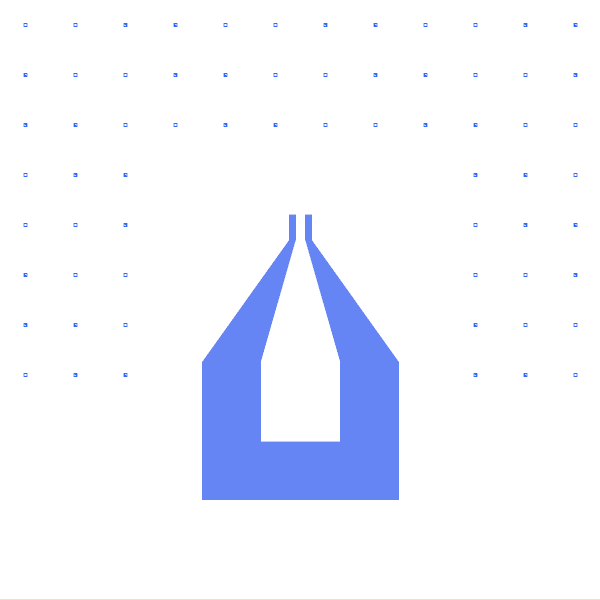

**On the chip so far:** 3 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** 3 component(s) `Launch_Readout_Q_0`, `Launch_Readout_Q_1`, `Launch_Readout_Q_2`.

WindowsPath('examples/designs/metal/a7_ims2022_3q_s2_pads.png')

In [6]:
with d.batch():
    l0 = d.add("Launch_Readout_Q_0", "metal:LaunchpadWirebond", at=P(-2000, 2500), rot=-90, edge="n")
    l1 = d.add("Launch_Readout_Q_1", "metal:LaunchpadWirebond", at=P(2000, 2500), rot=-90, edge="n")
    l2 = d.add("Launch_Readout_Q_2", "metal:LaunchpadWirebond", at=P(-2000, -2500), rot=90, edge="s")
rebuild(d)
display(Markdown(pads_md(d)))
px, py = port_xy(d, "Launch_Readout_Q_2.tie")
layout_step(d, OUT / "a7_ims2022_3q_s2_pads.png", box=(px - 300, -750, px + 300, -150), size=(600, 600), width=300)

## Design 3 · Readout: the feedline tees, `Q_2`'s series capacitor and their lines

The readout line needs no qubit, so it comes first. Two `metal:CapNInterdigitalTee`s sit on the north feedline (each couples a readout to it); a
`metal:CapNInterdigital` is `Q_2`'s series capacitor to its own pad. The tees sit 1.5 mm
either side of the chip's axis, 2.25 mm north of its centre; `Q_2`'s capacitor 2.25 mm south, below its pad.

**Lines** (`cpw`): north launchpad → tee 0 → tee 1 → north launchpad (three routes, one elbow at each pad); `Q_2`'s
capacitor joins its south pad with a short straight (Metal's `RouteStraight`). Each leaves its pad along the pad axis,
so moving the pads to the edge (Design 2) only lengthened them.

tee ports: ['prime_end', 'prime_start', 'second_end'] | cap ports: ['north_end', 'south_end']


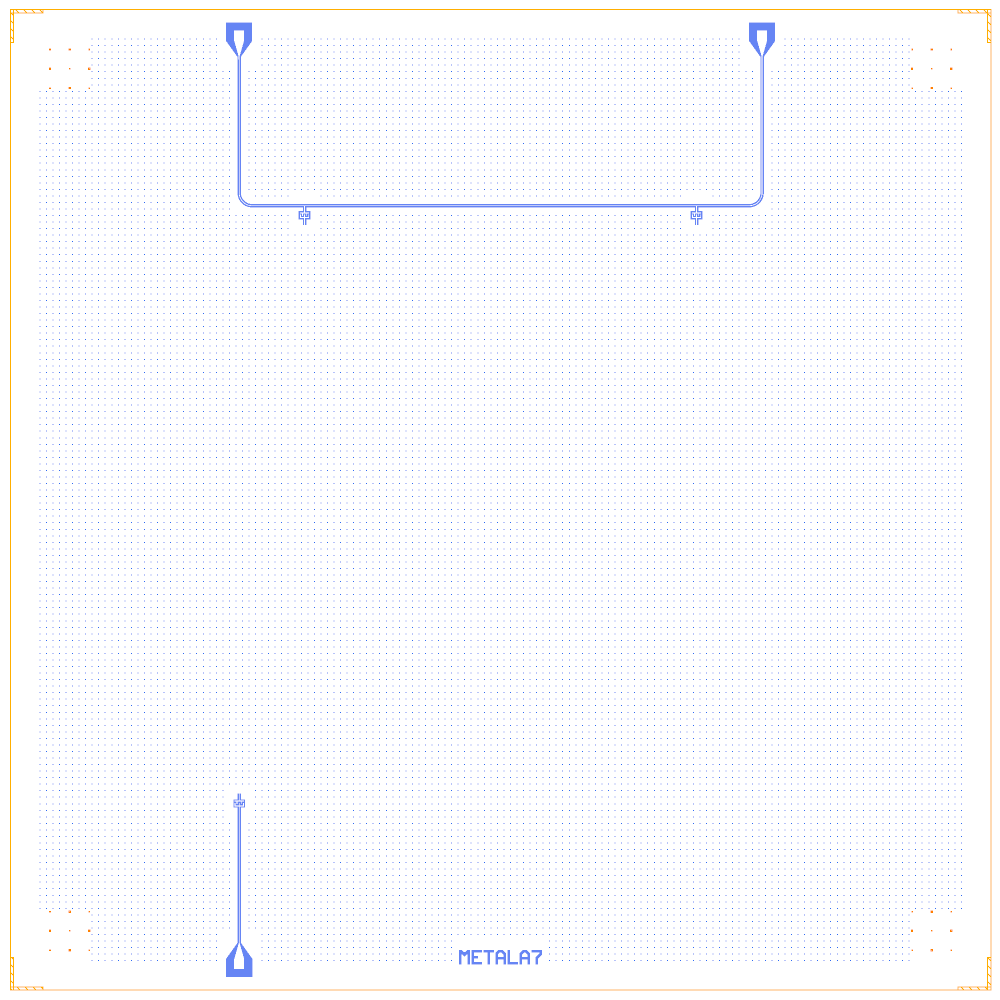

**On the chip so far:** 3 pads · 0 qubits · 3 other components · 4 routes · 0 declared couplings. **This step added** 3 component(s) `Cap_Readout_Q_2`, `Cap_Readout_Q_0`, `Cap_Readout_Q_1` and 4 route(s) `TL_Readout_Q_0`, `TL_Readout_Q_01`, `TL_Readout_Q_1`, `TL_Readout_Q_2`.

WindowsPath('examples/designs/metal/a7_ims2022_3q_s3_readout_line.png')

In [7]:
with d.batch():
    c2 = d.add("Cap_Readout_Q_2", "metal:CapNInterdigital", at=P(-2000, -2250))
    t0 = d.add("Cap_Readout_Q_0", "metal:CapNInterdigitalTee", at=P(-1500, 2250))
    t1 = d.add("Cap_Readout_Q_1", "metal:CapNInterdigitalTee", at=P(1500, 2250))
    # feedline: launchpad → tee 0 → tee 1 → launchpad
    d.route("TL_Readout_Q_0", t0.prime_start, l0.tie, r=R, nodes=[(1000, 5250)])
    d.route("TL_Readout_Q_01", t0.prime_end, t1.prime_start)
    d.route("TL_Readout_Q_1", t1.prime_end, l1.tie, r=R, nodes=[(5000, 5250)])
    d.route("TL_Readout_Q_2", c2.south_end, l2.tie, r=30)   # Metal RouteStraight (longer now: the pad is at the edge)
print("tee ports:", sorted(t0.ports), "| cap ports:", sorted(c2.ports))
layout_step(d, OUT / "a7_ims2022_3q_s3_readout_line.png", size=(1000, 1000), width=440)

## Design 4 · Qubit placement: three pocket transmons, junctions sized for the targets

**The qubits.** `metal:TransmonPocket6` is Metal's pocket transmon with up to six connection pads, drawn by the
wrapper with the tutorial's tuned options: 425 µm pads in a 650 µm pocket (`pad_gap` 28 µm on `Q_0`/`Q_1`), a
`readout` pad and two bus pads each (`pad()` builds Metal's `connection_pads` entries).

**The junctions: sized for the targets.** Unlike most Metal examples, this one states its qubit frequencies, so each
Quantcore trilayer junction is sized for its target with the qubit's C_Σ: `size_junction(f_q, C_Σ)` solves the
straight finger on the PDK rule (Nb Δ 1.4 meV, R_n·A 13.5 kΩ·µm², C_J 50 fF/µm²; bent finger 0.6 µm) and
`trilayer_junction(..., lj_nH=)` draws it and returns its L_J and C_J for the LOM and the FEM junction port. C_Σ
(without the junction) comes from this design's LOM before the rebuild. These pockets are small, so 4.8–5.2 GHz needs
L_J ≈ 15 nH, i.e. **R_n ≈ 98–102 kΩ, outside the 40–50 kΩ window**: the DRC flags it (`pdk_rn`); a 45 kΩ junction would
put the qubits at ≈ 7.0–7.3 GHz, still in the 4–8 GHz band. The values are the source's choice, so they are flagged,
not retuned.

`Q_0` and `Q_1` sit 1.25 mm either side of the axis, 0.5 mm north of the centre, `Q_2` 1.35 mm south: a triangle, each
qubit's `readout` pad towards its tee or capacitor and its two bus pads towards the other two qubits. The second picture
zooms on `Q_0` with its three pads.

Q_0: L_J 15.3055 nH, C_J 6.6 fF, R_n 104 kΩ, fingers 0.22 × 0.6 µm, f_q 4.84 GHz (analytic); R_n 104.2 kΩ is outside the process window 40–50 kΩ (f_q 4.8 GHz with C_Σ 62.2 fF needs E_J/h 10.5 GHz)
Q_1: L_J 14.64 nH, C_J 6.9 fF, R_n 98 kΩ, fingers 0.23 × 0.6 µm, f_q 5.02 GHz (analytic); R_n 98.5 kΩ is outside the process window 40–50 kΩ (f_q 5 GHz with C_Σ 60.8 fF needs E_J/h 11.1 GHz)
Q_2: L_J 14.64 nH, C_J 6.9 fF, R_n 98 kΩ, fingers 0.23 × 0.6 µm, f_q 5.20 GHz (analytic); R_n 98.0 kΩ is outside the process window 40–50 kΩ (f_q 5.2 GHz with C_Σ 56.2 fF needs E_J/h 11.1 GHz)
Q_0 ports: ['bus_01', 'bus_02', 'readout', 'squid_a', 'squid_b']


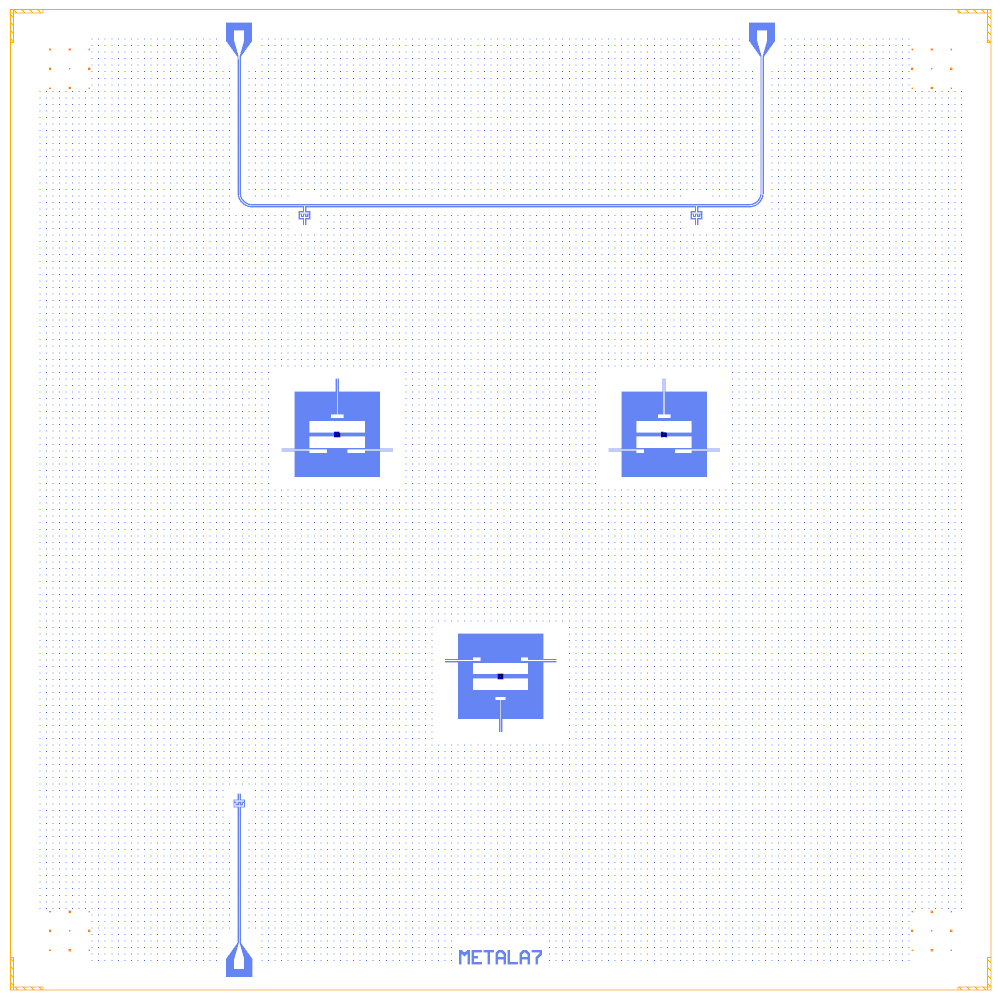

**On the chip so far:** 3 pads · 3 qubits · 3 other components · 4 routes · 0 declared couplings. **This step added** 3 component(s) `Q_0`, `Q_1`, `Q_2`.

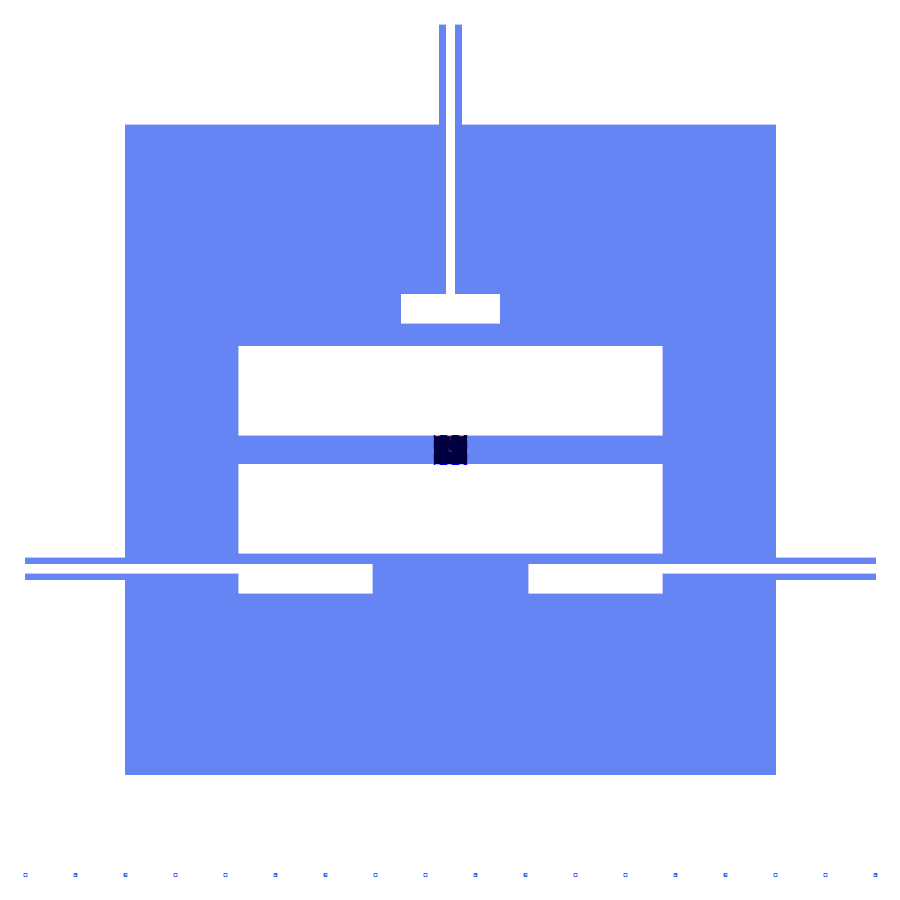

WindowsPath('examples/designs/metal/a7_ims2022_3q_step_parts.png')

In [8]:
# Quantcore trilayer junctions, each sized on the PDK rule (Nb Δ 1.4 meV; R_n·A 13.5 kΩ·µm², C_J 50 fF/µm² assumed) for
# the tutorial's target f_q with the qubit's C_Σ (fF, without the junction) from this design's LOM before the rebuild
# (QuTiP f_q 5.094 / 5.364 / 5.563 GHz with the source's 14.9 / 13.9 / 14.0 nH + 2 fF)
C_SIGMA = {"Q_0": 55.7, "Q_1": 53.9, "Q_2": 49.3}
SIZED = {q: size_junction(TARGETS[q]["f_q_GHz"], c, c_includes_junction=False) for q, c in C_SIGMA.items()}
JJP, JJ = {}, {}
for q, s in SIZED.items():
    JJP[q], JJ[q] = trilayer_junction("metal:TransmonPocket6", lj_nH=s.lj_nH)
    print(f"{q}: L_J {JJ[q]['Lj_nH']} nH, C_J {JJ[q]['Cj_fF']} fF, R_n {s.rn_kohm:.0f} kΩ, fingers {s.finger_width} × "
          f"{s.second_finger_width} µm, f_q {s.f_q_drawn_GHz:.2f} GHz (analytic)" + "".join(f"; {n}" for n in s.notes))
with d.batch():
    pocket = dict(pad_width=425, pocket_height=650)
    q0 = d.add("Q_0", "metal:TransmonPocket6", at=P(-1250, 500), pad_gap=28, junction=JJ["Q_0"], **JJP["Q_0"], **pocket,
               connection_pads={"readout": pad(0, 1, 100, 22), "bus_01": pad(1, -1, 135, 10), "bus_02": pad(-1, -1, 135, 10)})
    q1 = d.add("Q_1", "metal:TransmonPocket6", at=P(1250, 500), pad_gap=28, junction=JJ["Q_1"], **JJP["Q_1"], **pocket,
               connection_pads={"readout": pad(0, 1, 100, 20), "bus_01": pad(-1, -1, 60, 10), "bus_12": pad(1, -1, 130, 10)})
    q2 = d.add("Q_2", "metal:TransmonPocket6", at=P(0, -1350), junction=JJ["Q_2"], **JJP["Q_2"], **pocket,
               connection_pads={"readout": pad(0, -1, 80, 50), "bus_02": pad(-1, 1, 60, 10), "bus_12": pad(1, 1, 60, 10)})
print("Q_0 ports:", sorted(q0.ports))
layout_step(d, OUT / "a7_ims2022_3q_s4_qubits.png", size=(1000, 1000), width=440)
qx, qy = P(-1250, 500)
snap(d, OUT / "a7_ims2022_3q_step_parts.png", box=(qx - 450, qy - 450, qx + 450, qy + 450), size=(900, 900), width=360)

## Design 5 · Readout: the three λ/2 readout serpentines

Each qubit's `readout` pad gets a λ/2 line of the tutorial's tuned length: `Readout_0` (8800 µm) and `Readout_1`
(8500 µm) to the coupled port `second_end` of their feedline tee, `Readout_2` (8300 µm) to the north pin of `Q_2`'s
series capacitor. They are serpentines through waypoints (`serp`: runs 200 µm apart, like Metal's 200 µm meander
spacing), north of `Q_0` / `Q_1` and west of `Q_2`, with Metal's 99 µm fillet.

**No meander needed.** The run extents (197.269, 5802.731 and 149.852 µm) are solved so that each waypoint path is
already the full length to 0.01 µm. The router (2026-11-18) then draws the path as it is: a `meander` route within
0.01 µm of its length gets no meander, a small leftover would go into the free corners' bend radii (trimmed by at
most 5 %, in practice by nm), and only a real leftover gets a KQC `Meander`. So the serpentines are drawn exactly on
their waypoints.

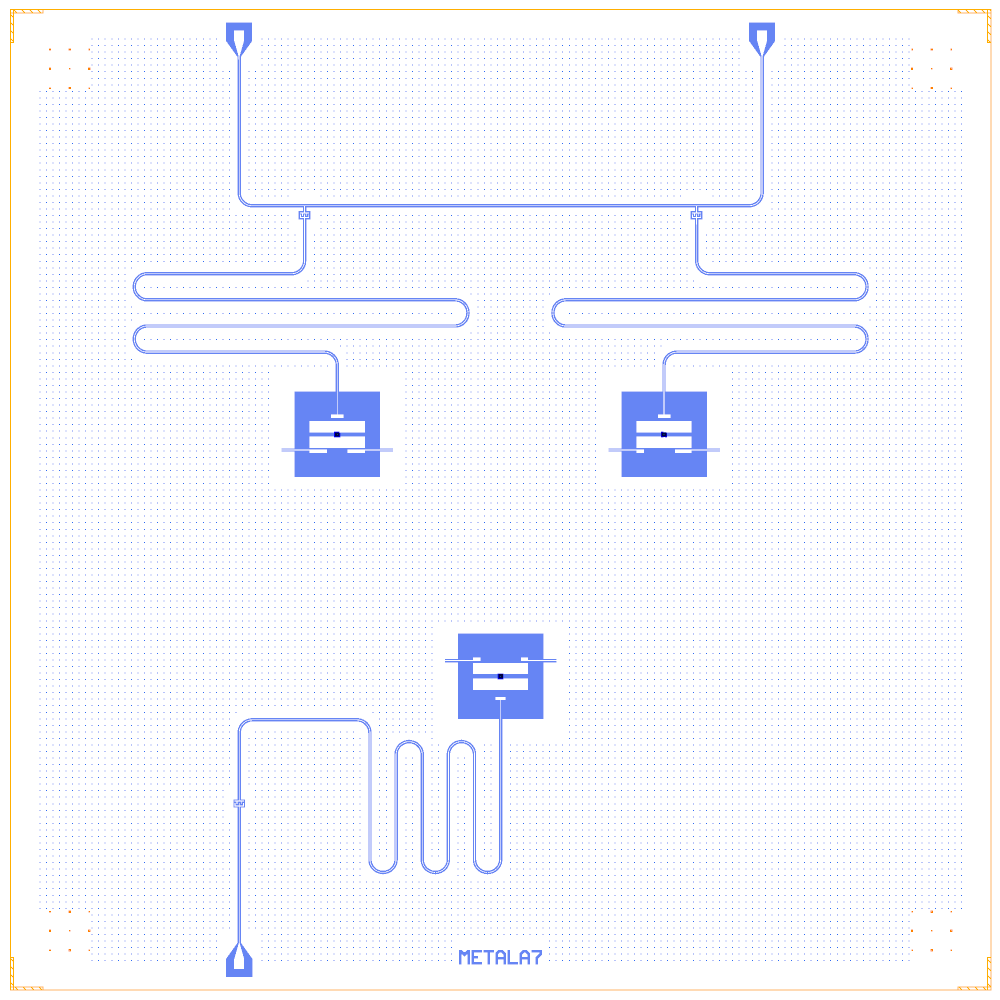

**On the chip so far:** 3 pads · 3 qubits · 3 other components · 7 routes · 0 declared couplings. **This step added** 3 route(s) `Readout_0`, `Readout_1`, `Readout_2`.

WindowsPath('examples/designs/metal/a7_ims2022_3q_s5_readouts.png')

In [9]:
with d.batch():
    # λ/2 readouts as serpentines (runs 200 µm apart, like Metal's 200 µm meander spacing), sized to their lengths
    # to 0.01 µm (the router's length-fixing `meander` then has nothing left to draw as a kink)
    d.route("Readout_0", q0.readout, t0.second_end, meander=8800, r=R,
            nodes=serp((1750, 4130), [197.269, 2750, 197.269], 200) + [(1500, 4730)])
    d.route("Readout_1", q1.readout, t1.second_end, meander=8500, r=R,
            nodes=serp((4250, 4130), [5802.731, 3400, 5802.731], 200) + [(4500, 4730)])
    d.route("Readout_2", q2.readout, c2.north_end, meander=8300, r=R,
            nodes=serp((3000, 1000), [149.852, 1150, 149.852, 1150, 149.852], -200, vertical=True) + [(2000, 1317), (1000, 1317)])
layout_step(d, OUT / "a7_ims2022_3q_s5_readouts.png", size=(1000, 1000), width=440)

## Design 6 · Coupling: three λ/2 buses, all-to-all

The qubits couple through three fixed-length λ/2 buses with the tutorial's tuned lengths: `Bus_01` (9550 µm) between
`Q_0` and `Q_1` meanders between them as in the source; `Bus_02` (9350 µm) and `Bus_12` (9700 µm) run beside the
qubits and meander on their vertical segment (`.set(meander_segment=3)`). Their waypoint paths are much shorter than
their lengths, so here the router does draw a KQC `Meander` for the leftover, with no more turns than keep each turn
at least the 99 µm bend radius wide.

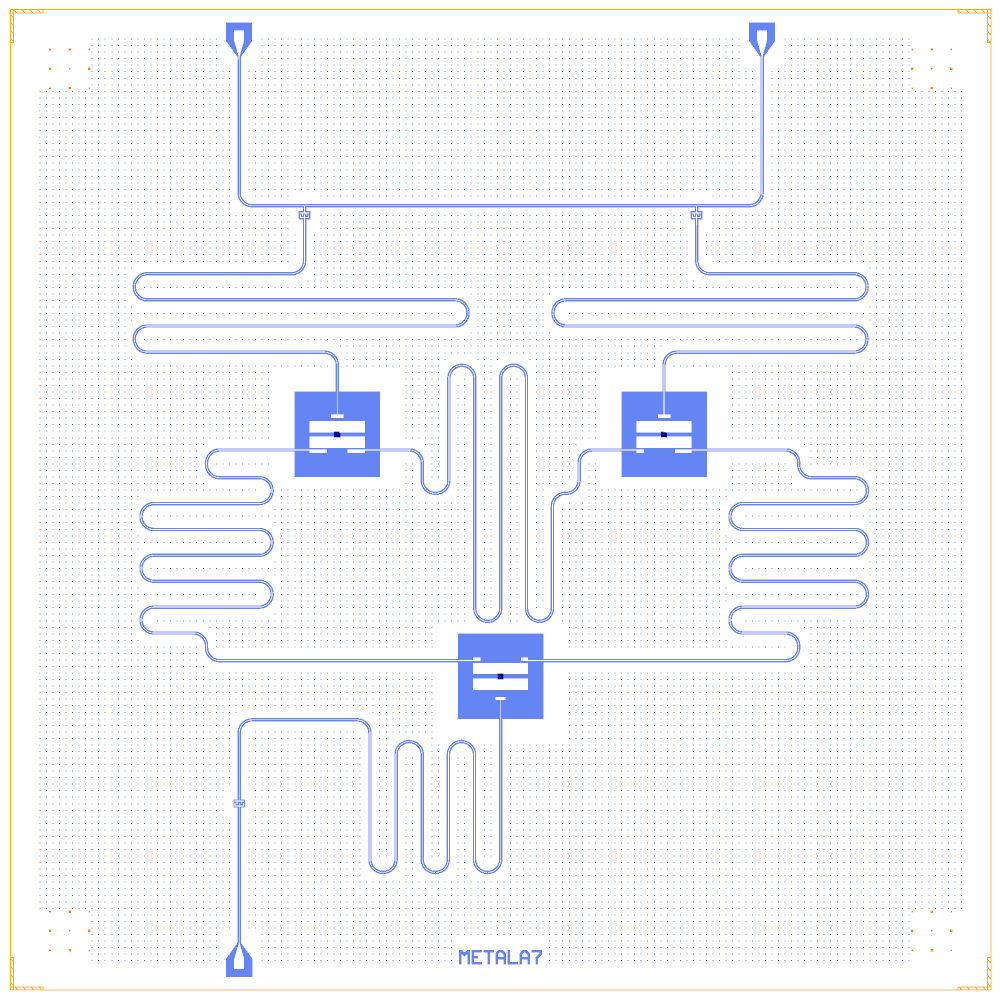

**On the chip so far:** 3 pads · 3 qubits · 3 other components · 10 routes · 0 declared couplings. **This step added** 3 route(s) `Bus_01`, `Bus_02`, `Bus_12`.

WindowsPath('examples/designs/metal/a7_ims2022_3q_s6_buses.png')

In [10]:
with d.batch():
    # buses (tuned lengths): Bus_01 meanders between the qubits, Bus_02 / Bus_12 beside them
    d.route("Bus_01", q0.bus_01, q1.bus_01, meander=9550, r=R, nodes=[(2400, 3381), (2400, 3050), (3600, 3050), (3600, 3381)])
    d.route("Bus_02", q0.bus_02, q2.bus_02, meander=9350, r=R, nodes=[(750, 3381), (750, 1770)]).set(meander_segment=3)   # on the vertical
    d.route("Bus_12", q1.bus_12, q2.bus_12, meander=9700, r=R, nodes=[(5280, 3381), (5280, 1770)]).set(meander_segment=3)
layout_step(d, OUT / "a7_ims2022_3q_s6_buses.png", size=(1000, 1000), width=440)

## Design 7 · Routing: control lines

None: the tutorial's qubits are fixed-frequency pockets with no flux or drive lines (it drives them through the
readout), so there is nothing to route here.

## Design 8 · The whole chip: sim groups, centring, save

**Sim groups** say what a FEM job cuts out of the chip: each qubit with its connection pads (`Q_0`, `Q_1`, `Q_2`, Q3D
C-matrix: the tutorial's Q3D step for the LOM). The 50 µm margins make each box cut every line once.

**Centring.** The PDK wants the chip content centred in the die. `center_in_die` measures the bounding box of everything placed
(components and routes) and shifts the design so its centre is the die centre (pads keep their 100 µm: they slide
back to the edge along it). The source is laid out about its chip centre and the pads now span the die in y, so the
shift is within the 50 µm tolerance (no move).

**Save.** The JSON is the deliverable. `save_design` writes it and compares it with the file it replaces (the
previous run's): the segments above changed how the chip is built, not the chip, so it should say *same design*. The
file keeps the previous key order (the capacitors were added before the qubits and the readouts before the buses
here), so `git diff` stays empty.

content shifted by (0.0, 0.0) µm


**Same design as before:** `examples/designs/metal/a7_ims2022_3q.json` is identical to the file it replaces (byte for byte). The segments changed how the chip is built, not the chip.

<Designer a7_ims2022_3q: 9 instances, 10 routes, live=False> → examples\designs\metal\a7_ims2022_3q.json
route lengths (µm): {'TL_Readout_Q_0': 1523, 'TL_Readout_Q_01': 2900, 'TL_Readout_Q_1': 1523, 'TL_Readout_Q_2': 969, 'Readout_0': 8800, 'Readout_1': 8500, 'Readout_2': 8300, 'Bus_01': 9550, 'Bus_02': 9350, 'Bus_12': 9700}


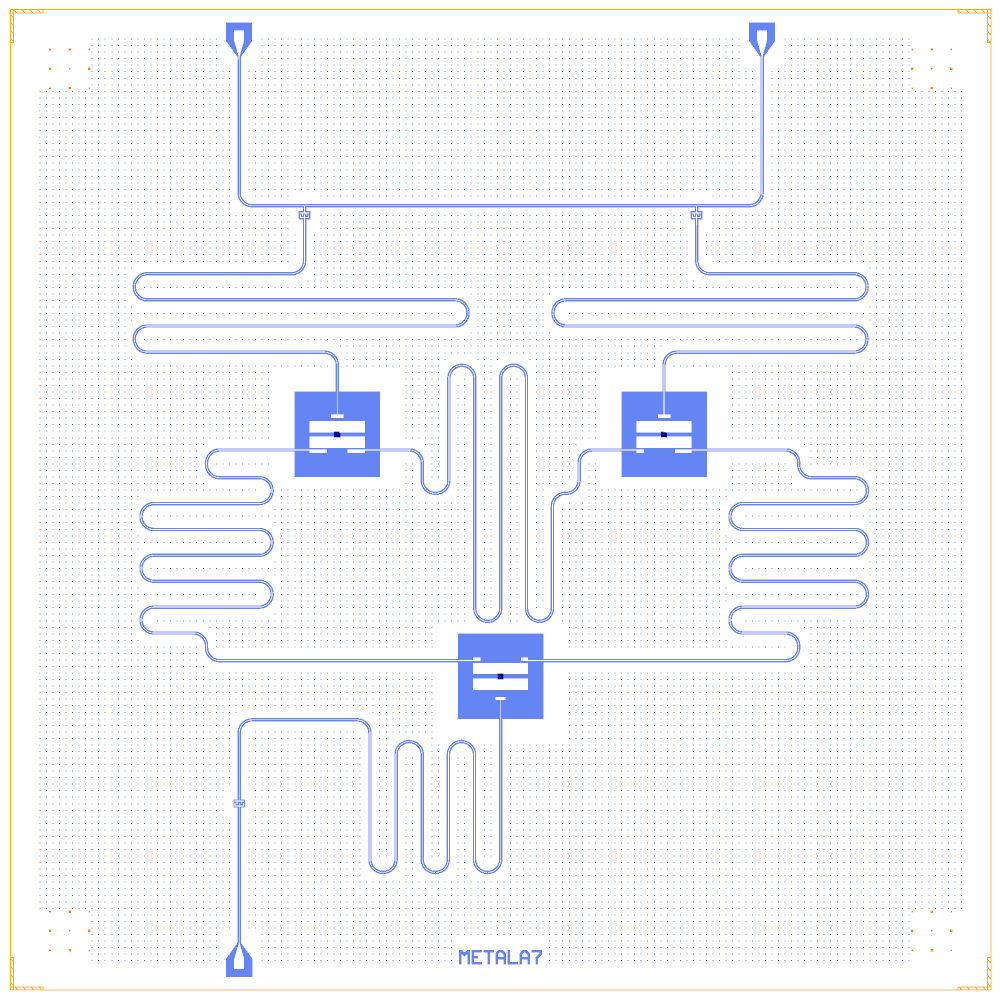

**On the chip so far:** 3 pads · 3 qubits · 3 other components · 10 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/metal/a7_ims2022_3q_step_routes.png')

In [11]:
# FEM boxes: each qubit with its pads (the tutorial's Q3D step); margins keep every line cut once
for q in ("Q_0", "Q_1", "Q_2"):
    d.sim_group(q, [q], margin_um=50, analyses=["q3d_cmatrix"])
shift = center_in_die(d)
rebuild(d)
print("content shifted by", shift, "µm")
DESIGN, same = save_design(d, OUT / "a7_ims2022_3q.json")
display(Markdown(same))
print(d, "→", DESIGN)
print("route lengths (µm):", {k: round(v) for k, v in d.result.route_lengths().items()})
layout_step(d, OUT / "a7_ims2022_3q_step_routes.png", size=(1000, 1000), width=440)

# Check: DRC and netlist

The plugin's *Check* step: the design rules, then the lumped circuit the layout turns into.

## Check 1 · DRC

`d.drc()` checks connectivity (every port routed or snapped, route ends resolved), crossings, overlaps, the chip
box and the frame. It has three kinds of findings:
- **errors** (open, short, crossing, outside the chip): the design is broken; there must be none;
- **warnings** (an unused port, two component boxes overlapping): worth a look, often by design;
- **PDK design warnings** (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): the design is valid but leaves a PDK
  margin. They are flagged, never fixed by retuning: the values are the source's.

Expected here (from the v1 run): **no errors**, six `dangling_port` warnings (`squid_a` / `squid_b` of the three qubits, the
junctions' attachment points: the qubit cell draws the junction itself, nothing is routed there) and **three PDK
design warnings** `pdk_rn` (`Q_0`/`Q_1`/`Q_2` R_n ≈ 98–102 kΩ: the junctions are sized for the tutorial's 4.8 / 5.0 /
5.2 GHz targets on small pockets, see Design 4). No `pad_edge` (the pads are at 100 µm) and no `pdk_fq` (all targets
are inside 4–8 GHz).

`pdk_report(d)` sums up the PDK side: the cheese source, how far the content centre is from the die centre, the
junction types and the design warnings.

In [ ]:
rep = d.drc()
display(Markdown(drc_md(rep)))
display(Markdown(pdk_report(d)))

## Check 2 · Netlist

`d.lom()` turns the layout into a lumped circuit: a `TransmonPocket6` gives two floating pad nodes with the junction
between them, plus a node per connection pad. The buses are λ/2 `TLres` between two pads; `Readout_0`/`Readout_1` are
λ/2 (pad → interdigital tee on the feedline between two 50 Ω ports), `Readout_2` is λ/2 (pad → series cap → 50 Ω
port). The port map shows where `Q_0`'s ports landed.

In [ ]:
lb = d.lom()
show_netlist(lb)
print({k: v for k, v in lb.port_map.items() if k.startswith(("Q_0.", "Cap_Readout_Q_0."))})

# LOM: simulate the lumped circuit, and plot it

## LOM 1 · The LOM simulation and the tutorial's targets

Each qubit with its readout (and the feedline or its pad); then each bus with the two qubits it joins (QuCat normal
modes, static ZZ from QuTiP). Targets in brackets are the tutorial's (f_q 4.8 / 5.0 / 5.2 GHz, α −300 MHz, readouts
6.8 / 7.0 / 7.2 GHz, buses 5.8 / 6.0 / 6.2 GHz). The junctions are sized for the targets from the analytic C_Σ, so f_q
should land within a few % of them; the readouts and buses are the tutorial's tuned lengths on sapphire with the
analytic pad model, so they sit a few % above target. The tutorial tuned against Q3D C-matrices: the per-qubit Q3D jobs
(Simulate 2) are what Results 3 replaces the pad estimates with.

In [ ]:
feed = ["Launch_Readout_Q_0", "Launch_Readout_Q_1", "TL_Readout_Q_0", "TL_Readout_Q_01", "TL_Readout_Q_1",
        "Cap_Readout_Q_0", "Cap_Readout_Q_1"]
read = {"Q_0+read": ["Q_0", "Readout_0"] + feed, "Q_1+read": ["Q_1", "Readout_1"] + feed,
        "Q_2+read": ["Q_2", "Readout_2", "Cap_Readout_Q_2", "TL_Readout_Q_2", "Launch_Readout_Q_2"]}
results = simulate_groups(d, read)
display(Markdown(groups_md(results, TARGETS)))
buses = {"Q_0+Bus_01+Q_1": ["Q_0", "Bus_01", "Q_1"], "Q_0+Bus_02+Q_2": ["Q_0", "Bus_02", "Q_2"],
         "Q_1+Bus_12+Q_2": ["Q_1", "Bus_12", "Q_2"]}
coupled = simulate_groups(d, buses, max_modes=3)
for g, res in coupled.items():
    display(Markdown(f"**{g}, QuCat normal modes:**\n\n" + modes_md(res)))
display(Markdown("**Static ZZ (QuTiP):**\n\n" + zz_md(coupled)))

## LOM 2 · The LOM in two plots

The same results as pictures: (a) every normal mode of each simulated group (QuCat; circles are qubits, squares
resonators; filled markers are the QuTiP dressed values; red bars the tutorial's targets), (b) the dispersive shift |χ|
of each readout. From the v1 run: the qubits sit on their targets (4.84 / 5.02 / 5.20 GHz), the readouts 1–1.6 % above
theirs, and in the bus groups the buses at 6.24 / 6.36 / 6.15 GHz against 5.8 / 6.0 / 6.2 GHz.

In [ ]:
plot_lom({**results, **coupled}, OUT / "a7_ims2022_3q_lom.png", targets=TARGETS, title="a7: LOM per sub-circuit")

## LOM 3 · One geometry change, by hand

Before the FEM, a hand-made design step: copy the saved design (`design_copy`: a non-live Designer that never writes over the
JSON), change one property — here `Q_0`'s readout connection pad, 100 → 120 µm wide (the tutorial's own knob for the
readout coupling) — rebuild, re-run the LOM of `Q_0` with its readout and the feedline, and compare. A wider pad
couples the readout more strongly: |χ| grows, and the extra pad capacitance pulls f_q and f_r down slightly; κ,
set by the tee on the feedline, hardly moves.

In [ ]:
d2 = design_copy(DESIGN)
d2["Q_0"].set(connection_pads={"readout": pad(0, 1, 120, 22), "bus_01": pad(1, -1, 135, 10),
                               "bus_02": pad(-1, -1, 135, 10)})   # readout pad 100 → 120 µm
after = simulate_groups(d2, {"Q_0+read": read["Q_0+read"]})
display(Markdown(params_delta_md({"Q_0+read": results["Q_0+read"]}, after)))

> **Simulation PC (32 GB+ RAM).** The cells below solve FEM jobs in AEDT. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

# Simulate: export to HFSS, the component and eigenmode simulations, the full-wave run

The plugin's *Simulate* step. The LOM above uses analytic capacitance estimates; a finite-element job measures them.
Each job is a sim group cut out of the chip, written to `build/jobs/<design>_<group>_<analysis>/`. With
`RUN_FEM = False` (the default) the jobs are only exported: the cells load results that were solved and kept before
(in `examples/designs/metal/fem/<job>/`), and otherwise say what would appear.

## Simulate 1 · Export to HFSS

The LOM uses analytic capacitance estimates; a finite-element job measures them. `export_sims` cuts each sim group
out of the chip (the box set by `sim_group`), puts ports where lines leave the box and writes a job folder under
`build/jobs/`. Simulation exports never get cheese, and airbridges are dropped unless asked for.

One **Q3D C-matrix** job per qubit with its connection pads (the tutorial's Q3D step for the LOM: island,
pad and bus-pad capacitances). A box around an 8–9 mm readout serpentine would cut the neighbouring meanders, so no readout
box is exported; the eigenmode job (Simulate 3) is the `Q_0` box of the same sim group.

`FEM_FAST` (the switch at the top) picks the fast test settings for every job exported from here on. With
`RUN_FEM = True` the next cells solve each Ansys job in a **new batch, non-graphical** AEDT 2024 R1 (or newer), so an
AEDT window you have open is never touched. The command-line equivalent is `qcc hfss solve build/jobs/<job>`.

In [ ]:
FEM_FAST = fem_fast(FEM_FAST)                    # the switch from the top: fast test settings, or as written
KEEP = fem_keep_dir(DESIGN)                      # examples/designs/metal/fem/: solved results are kept here
jobs = export_sims(DESIGN)                       # Q3D C-matrix: one job per sim group
jobs_eig = export_sims(DESIGN, ["Q_0"], analysis="eigenmode_epr")   # the Q_0 box in eigenmode (no new group)
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))

## Simulate 2 · Component simulation: the Q3D C-matrices

The capacitance of each qubit with its connection pads: `Q_0`, `Q_1` and `Q_2` (the tutorial's own Q3D step: the two
pocket pads, the readout pad and the two bus pads, and the lines the box cuts, as named nets). Each net is named after
its LOM node, so the matrix goes straight into the circuit (Results 3). `fem_stage` solves each job with `RUN_FEM`,
else loads its kept results, else says that there are none.

In [ ]:
keep_q3d = fem_stage(jobs, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · q3d": k for g, k in keep_q3d.items()})))
for g, k in keep_q3d.items():
    if k:
        display(Markdown(cmatrix_md(k)))

## Simulate 3 · Eigenmode simulation

The `Q_0` box in HFSS eigenmode (the same sim group, another analysis; nothing is added to the design): the junction is
a lumped L_J ‖ C_J sheet, and the readout and the two buses the box cuts end in 50 Ω there, so the qubit mode's Q is
that loading, not a T1 of the chip. pyEPR (run inside qcc's own AEDT, never KQC's `run_pyepr_t1_estimate.py`) turns
the junction's energy participation into `Q_0`'s dressed f_q and α, to compare with the LOM and with the tutorial's
4.8 GHz / −300 MHz.

In [ ]:
keep_eig = fem_stage(jobs_eig, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · eigenmode": k for g, k in keep_eig.items()})))

## Simulate 4 · Full-wave (driven) run

Not exported for this chip: the full-wave run needs a box with the readout and the feedline in it, and a box round an
8–9 mm readout serpentine holds the neighbouring meanders (Simulate 1). The readouts' f_r, κ and χ come from the LOM
on the Q3D C-matrices instead (Results 3).

# Results: plot, read the values, compare with the LOM, feed back, iterate

The plugin's *Results* step: what the FEM found, against the LOM and against a target, and the design change that
moves the chip towards the target.

## Results 1 · Plot the eigenmodes

(a) each mode's frequency over the adaptive passes (how the mesh converged), (b) the final modes, frequency against
Q, coloured by the junction participation p_J (≈ 1: the qubit), with the LOM's `Q_0` frequency as a dashed line. The
table below lists the modes and the pyEPR values.

In [ ]:
lom_f = {"Q_0": results["Q_0+read"].params.get("Q_0.f_q_GHz")}
plot_eigenmodes(keep_eig, OUT / "a7_ims2022_3q_eigenmodes.png", lom=lom_f)
for g, k in keep_eig.items():
    if k:
        display(Markdown(eigen_md(k)))

## Results 2 · The values

The eigenmode job in the LOM's terms: `Q_0`'s mode is the one its junction participates in most; f_q is pyEPR's
dressed frequency, α its self-Kerr, next to the tutorial's targets. There is no readout in the box (`epr_values` gets
a placeholder readout, and only `Q_0`'s values are kept).

In [ ]:
fem_q0 = {}
if keep_eig["Q_0"]:
    fem_q0 = {k: v for k, v in epr_values(keep_eig["Q_0"], {"Q_0": "none"}, {"none": 0.0}).items() if k.startswith("Q_0.")}
if fem_q0:
    display(Markdown("| quantity | FEM | target |\n|---|---|---|\n" + "\n".join(
        f"| `{k}` | {v:.5g} | {TARGETS['Q_0'].get(k.split('.', 1)[1], '–')} |" for k, v in fem_q0.items())))
else:
    print("No eigenmode results yet (RUN_FEM = True): this table would list Q_0's f_q and α from pyEPR, next to the "
          "tutorial's 4.8 GHz and -300 MHz.")

## Results 3 · FEM against the LOM

**LOM on the Q3D C-matrix:** `fill` replaces the capacitance estimates of each qubit (its pads and connection pads) by
its job's C-matrix values (matched by net name; the readout, the tee and the feedline keep their estimates) and the
same LOM runs again: f_q, α, f_r, χ and κ of each qubit with its readout. **FEM directly:** `Q_0`'s eigenmode values
(Results 2). The left column is the LOM on the component estimates (LOM 1).

In [ ]:
from quantcore_circuits.circuit.fill import fill

rows = []
for k in (0, 1, 2):
    q, g = f"Q_{k}", f"Q_{k}+read"
    lom_p = results[g].params
    keys = [f"{q}.f_q_GHz", f"{q}.alpha_MHz", f"Readout_{k}.f_GHz", f"Readout_{k}.chi_MHz", f"Readout_{k}.kappa_MHz"]
    if keep_q3d.get(q):
        on_fem = simulate(fill(d.lom(select=read[g]).model, DESIGN, keep_q3d[q]), max_modes=2).params
        rows += [(key, lom_p.get(key), on_fem.get(key), "LOM on the Q3D C-matrix") for key in keys]
rows += [(key, results["Q_0+read"].params.get(key), v, "Q_0 eigenmode + pyEPR") for key, v in fem_q0.items()]
if rows:
    display(Markdown(fem_vs_lom_md(rows)))
else:
    print("No FEM results yet: with RUN_FEM = True this table puts f_q, α, f_r, χ and κ of the LOM next to the LOM "
          "on each qubit's Q3D C-matrix and next to Q_0's eigenmode, with the difference in %.")

## Results 4 · Feedback: one step towards the tutorial's targets

This chip has its own targets, the tutorial's, set in Design 1 and saved in the JSON: f_q 4.8 / 5.0 / 5.2 GHz, α −300
MHz, readouts 6.8 / 7.0 / 7.2 GHz, buses 5.8 / 6.0 / 6.2 GHz. `target_copy(DESIGN, {})` writes the design with those
targets (nothing added) to `build/a7_ims2022_3q_target.json`, and the feedback works on that copy.

`loop.analyse` runs the estimators (QuCat, SQcircuit, scqubits, Metal LOM) on every qubit–readout pair of the
circuit — on the Q3D values where a solve was kept — and picks one value per quantity (the consensus).
`loop.feedback` anchors a surrogate on that point and proposes the knobs that put the targets inside their
tolerances: L_J for f_q, the pocket's `pad_width` (the island knob) for α, the readout meander's length for f_r. The
proposal is written as revision 1, built and netlist-checked. From the v1 run the qubits are within 1 % of their
targets, α is 25–40 % larger in magnitude (−374 … −418 MHz) and the readouts 1–1.6 % high. A higher readout needs a
longer line, which the router can give it (a meander on top of the waypoints); a shorter one could not go below its
waypoint path.

**No PDK window here.** The junctions are already outside the 40–50 kΩ window (Design 4: R_n ≈ 98–102 kΩ):
`pdk_lj_bounds` would pull every L_J into it, i.e. the qubits to ≈ 7 GHz, away from the tutorial's targets. So the
feedback runs without those bounds and the DRC keeps flagging `pdk_rn`: the targets are the source's. A revision that
changes `pad_width` also moves the bus pins (`loc_W` ±1), so read its DRC line.

In [ ]:
from quantcore_circuits import loop
from quantcore_circuits.assembly.drc import check

DESIGN_T = target_copy(DESIGN, {})               # the design's own targets (the tutorial's), nothing added
BOUNDS = None                                    # no PDK R_n window: the targets need L_J outside it (see above)
FILL = [k for k in keep_q3d.values() if k] or None   # kept Q3D results fill the circuit; None: the LOM estimates
an0 = loop.analyse(str(DESIGN_T), FILL, readout=False)
display(Markdown(consensus_md(an0, only_targets=True)))
prop, rev1, rev1_build = loop.feedback(an0, design_source=str(DESIGN_T), bounds=BOUNDS)
display(Markdown(proposal_md(prop)))
now = {r.param: r.chosen for r in an0.rows}
display(Markdown(before_after_md({k: now.get(k) for k in prop.residuals}, {k: prop.predicted[k] for k in prop.residuals})))
print("revision 1:", rev1, "· DRC:", "clean" if check(rev1_build).ok else "ERRORS")

## Results 4b · The buses: a first-order rule

The buses are not qubit–readout pairs (each joins two qubits), so `loop.feedback` does not see their targets (its
notes say so). They get a first-order rule in the notebook instead: a λ/2 line resonates at f ∝ 1/ℓ, so
**ℓ ← ℓ · f_now / f_target** (`rule_step`, exponent −1), with f_now the bus's normal mode in its LOM group (LOM 1). From
the v1 run that makes `Bus_01` and `Bus_02` longer (6.24 → 5.8 and 6.36 → 6.0 GHz) and `Bus_12` slightly shorter
(6.15 → 6.2 GHz; still far above its waypoint path). The new lengths are set on a copy of the design (`design_copy`),
the three bus groups are simulated again, and the copy is saved and DRC-checked (longer meanders take more room:
read the DRC line).

In [ ]:
BUS = {"Bus_01": "Q_0+Bus_01+Q_1", "Bus_02": "Q_0+Bus_02+Q_2", "Bus_12": "Q_1+Bus_12+Q_2"}


def bus_f(res, bus):
    """The bus's normal-mode frequency (GHz) in its LOM group (QuCat)."""
    return next((m.f_GHz for m in res.modes if m.label == bus), None)


d_b = design_copy(DESIGN, "_buses")              # the bus revision: the design file stays
before, after = {}, {}
for bus, g in BUS.items():
    l_now, f_now = float(d.data["routes"][bus]["length"]), bus_f(coupled[g], bus)
    l_new = round(rule_step(l_now, f_now, TARGETS[bus]["f_GHz"], -1.0), 2)
    d_b[bus].set(meander=l_new)
    before[f"{bus} ℓ (µm)"], before[f"{bus} f (GHz)"], after[f"{bus} ℓ (µm)"] = l_now, f_now, l_new
res_b = simulate_groups(d_b, {g: buses[g] for g in BUS.values()}, max_modes=3)
for bus, g in BUS.items():
    after[f"{bus} f (GHz)"] = bus_f(res_b[g], bus)
display(Markdown(before_after_md(before, after)))
rev_b = d_b.save(Path("build") / "a7_ims2022_3q_buses" / "rev1.json")
print("bus revision:", rev_b, "· DRC:", "clean" if check(str(rev_b)).ok else "ERRORS")

## Results 5 · Iterate to the targets

The feedback cell, repeated: analyse the revision → on target? → else feed back again → the next revision, until every
target is inside its tolerance or `MAX_ITER` revisions are made (`build/a7_ims2022_3q/revisions/`). Without `RUN_FEM`
each revision is judged on the LOM. With `RUN_FEM = True` each revision's three Q3D qubit jobs are exported and solved
first (`solve_rev`), so the loop closes on FEM values (each solve takes AEDT minutes). The table shows each iteration's
values against the targets and the knobs it moved; the plot the residual in tolerances (on target below 1).

Then the bus rule repeated for each bus (`rule_iterate`: the next step uses the exponent of the last two points, a
secant), until the bus is within 10 MHz of its target or `MAX_ITER` steps are made (LOM).

In [ ]:
def solve_rev(rev, k):
    """RUN_FEM: revision k's Q3D component jobs (the three qubit boxes), exported to build/jobs/rev<k>/ and solved."""
    jobs_k = export_sims(rev, root=f"build/jobs/rev{k}")
    kept = fem_stage(jobs_k, RUN_FEM, KEEP / f"rev{k}", force=RESOLVE, aedt=AEDT_MODE)
    return [v for v in kept.values() if v] or None


history, last, an_last = iterate_to_target(DESIGN_T, FILL, max_iter=MAX_ITER, bounds=BOUNDS,
                                           solve=solve_rev if RUN_FEM else None, an=an0)
display(Markdown(history_md(history)))
plot_iterations(history, OUT / "a7_ims2022_3q_iterate.png")
print("last design:", last, "· on target:", history[-1]["on_target"])


def bus_rev(bus):
    """evaluate(ℓ, it) for rule_iterate: a copy with the bus ℓ long, saved, and the bus mode of its LOM group."""
    def evaluate(length, it):
        d_k = design_copy(DESIGN, f"_{bus}_rev{it}")
        d_k[bus].set(meander=round(length, 2))
        path = d_k.save(Path("build") / "a7_ims2022_3q_buses" / f"{bus}_rev{it}.json")
        return bus_f(simulate_groups(d_k, {BUS[bus]: buses[BUS[bus]]}, max_modes=3)[BUS[bus]], bus), path
    return evaluate


for bus, g in BUS.items():
    hist_b = rule_iterate(bus_rev(bus), f"{bus}.f_GHz", f"{bus}.length", float(d.data["routes"][bus]["length"]),
                          TARGETS[bus]["f_GHz"], 0.010, -1.0, max_iter=MAX_ITER, start=(bus_f(coupled[g], bus), DESIGN))
    display(Markdown(f"**{bus}:**\n\n" + history_md(hist_b)))

# Fab: the mask, snapshots, summary

## Fab 1 · Build and export

The design JSON saved in Design 8 is the deliverable: `qcc build`, `qcc mask` and the KLayout plugin all read it.
The fab export writes only the PDK fab layers (1/0 etch, 3/0 keep-out, 2/0 + 4/0 junction fingers, 50–53/0 spacer,
100/0 chip boundary, 1000/0 + 1001/0 frame markers), with corner rounding and the cheese.

**Cheese: the original wins.** The A.7 notebook exports its GDS with Metal's `QGDSRenderer` and sets the cheese explicitly: `cheese_0_x/y = 3um` squares every `delta_x/y = 50um`, `no_cheese.buffer = 40um`, `cheese.view_in_file = {"main": {1: True}}` (`edge_nocheese` stays at its 200 µm default). So the original *has* cheese, and the precedence rule keeps the original's, not the PDK band. The chip carries Metal's rule as its `cheese` parameter (Design 1: `metal_cheese_rule(buffer=40, size=3, pitch=50)` = `{size, gap, rows, clearance, edge}`), so the build draws it into KQC's `ground_grid` layer over the whole free ground inside the frame's design area, clear of the 3/0 keep-outs by the buffer (the 3/0 keep-out already adds the PDK route margin round each CPW, so the holes sit a few µm further from the etch than in Metal). The layout, the snapshots and KLive show it, and `export_fab` / `qcc mask` keep it (`cheese source: build`, no PDK band added).

Command-line equivalents:
- `qcc build examples/designs/metal/<id>.json` (the layout and its KLayout sidecar);
- `qcc mask examples/designs/metal/<id>.json` (the fab file; `--no-cheese`, `--no-round`);
- `qcc sim build examples/designs/metal/<id>.json -g <group> -a q3d_cmatrix` (one FEM job).

In [ ]:
print("design file:", DESIGN)
CHEESE = True                                    # export_fab keeps the build's cheese (the original's rule)
display(Markdown(fab_layers_md(d, cheese=CHEESE, rounding=True)))

## Fab 2 · Snapshots

The full chip (compare the tutorial's last screenshot); `Q_0` with its three pads; its trilayer junction; the `Q_0`
interdigital tee on the feedline; the **fab mask** beside `Q_2` (1/0 etch with the original's 3 µm Metal cheese on
the free ground, 40 µm clear of the 3/0 keep-outs; the junction layers); and the die frame's south-west corner (dicing L on 1000/0, alignment grid on
1001/0). Positions are read from the design (after the centring shift).

In [ ]:
QX, QY = d.data["instances"]["Q_0"]["place"]["at"]
TX, TY = d.data["instances"]["Cap_Readout_Q_0"]["place"]["at"]
show_snapshot(d, OUT / "a7_ims2022_3q.png", size=(1200, 1200))
show_snapshot(d, OUT / "a7_ims2022_3q_q0.png", box=(QX - 450, QY - 450, QX + 450, QY + 450), width=420)
show_snapshot(d, OUT / "a7_ims2022_3q_jj.png", box=(QX - 40, QY - 40, QX + 40, QY + 40), width=300)
show_snapshot(d, OUT / "a7_ims2022_3q_tee.png", box=(TX - 200, TY - 250, TX + 200, TY + 100), size=(800, 700), width=360)
Q2X, Q2Y = d.data["instances"]["Q_2"]["place"]["at"]   # free ground south-east of Q_2 shows the 3 µm holes
snap_file(Path("build") / "a7_ims2022_3q_fab.oas", OUT / "a7_ims2022_3q_cheese.png",
          box=(Q2X - 500, Q2Y - 1100, Q2X + 700, Q2Y + 100), size=(1200, 1200), width=420)
show_snapshot(d, OUT / "a7_ims2022_3q_frame.png", box=(-750, -750, 150, 150), size=(900, 900), width=300);

## Summary

| | |
|---|---|
| matches the source | every Metal component with the tuned options, their positions, the route end pins and tuned lengths (buses 9550 / 9350 / 9700 µm, readouts 8800 / 8500 / 8300 µm), all stated targets |
| PDK changes | the 7.5 mm Quantcore die with the QCT frame; sapphire stack; the three launchpads 100 µm from the north / south edges (were 990 µm); trilayer junctions sized for 4.8 / 5.0 / 5.2 GHz; cheese = the original's 3 µm Metal cheese, drawn by the build; content centred (no shift needed) |
| differs | the bus / readout meander shapes (qcc router); from the v1 run: LOM f_q 4.84 / 5.02 / 5.20 GHz on the 4.8 / 5.0 / 5.2 GHz targets, α −374 / −382 / −418 MHz (target −300), readouts 6.88 / 7.11 / 7.24 GHz (targets 6.8 / 7.0 / 7.2; χ −1.26 / −1.31 / −0.56 MHz), buses 6.24 / 6.36 / 6.15 GHz in the bus groups (targets 5.8 / 6.0 / 6.2), static ZZ 22 / 81 / 37 kHz |
| PDK design warnings | 3 × `pdk_rn` (R_n ≈ 98–102 kΩ, sized for the source's targets) |
| layout | built in segments (die with the targets, pads, the readout line, qubits, readouts, buses, the whole chip); the saved JSON is the v1 notebook's |
| feedback | towards the tutorial's own targets on a copy: `loop.analyse` → `loop.feedback` → revisions (qubit–readout pairs; no PDK R_n bounds, the targets need L_J outside the window) and a first-order length rule for the three buses (LOM; FEM with `RUN_FEM`) |
| open | the FEM jobs (Q3D, the `Q_0` eigenmode) are exported, not solved (`RUN_FEM = False`): run with `RUN_FEM = True` to fill the Simulate and Results cells |